# 03 — Train and evaluate CNN
Trains the CNN and reports metrics only on the held-out speakers from Notebook 02.

In [7]:
from pathlib import Path
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
OUT=Path("anu_revision_output")
d=np.load(OUT/"speaker_split_mfcc.npz",allow_pickle=True)
Xtr,Xte,ytr,yte=d["X_train"],d["X_test"],d["y_train"],d["y_test"]
classes=d["classes"].astype(str)

In [14]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=Xtr.shape[1:]),

    tf.keras.layers.Conv2D(32, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [15]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=callbacks,
    shuffle=True
)

Epoch 1/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.1255 - loss: 2.5968 - val_accuracy: 0.0243 - val_loss: 2.6666 - learning_rate: 5.0000e-04
Epoch 2/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.2105 - loss: 2.3923 - val_accuracy: 0.0693 - val_loss: 2.6934 - learning_rate: 5.0000e-04
Epoch 3/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.2711 - loss: 2.2142 - val_accuracy: 0.0431 - val_loss: 2.6598 - learning_rate: 5.0000e-04
Epoch 4/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3380 - loss: 2.0279 - val_accuracy: 0.0824 - val_loss: 2.5519 - learning_rate: 5.0000e-04
Epoch 5/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.3876 - loss: 1.8487 - val_accuracy: 0.2491 - val_loss: 2.2580 - learning_rate: 5.0000e-04
Epoch 6/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.4411 - loss: 1.6675 - val_accuracy: 0.3390 - val_loss: 2.0109 - learning_rate: 5.0000e-04
Epoch 7/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.4970 

Held-out speaker accuracy: 0.5762527233115469
                  precision    recall  f1-score   support

             anu       0.49      0.50      0.50        66
   close browser       0.39      0.48      0.43        66
close calculator       0.47      0.45      0.46        66
            help       0.47      0.91      0.62        66
            mute       0.72      0.63      0.67        60
            next       0.50      0.70      0.58        66
    open browser       0.37      0.17      0.23        66
 open calculator       0.54      0.23      0.32        66
           pause       0.68      0.59      0.63        66
            play       0.93      0.61      0.73        66
        previous       0.66      0.70      0.68        66
      screenshot       0.65      0.83      0.73        66
           sleep       0.68      0.59      0.63        66
          unmute       0.75      0.68      0.71        66

        accuracy                           0.58       918
       macro avg       0

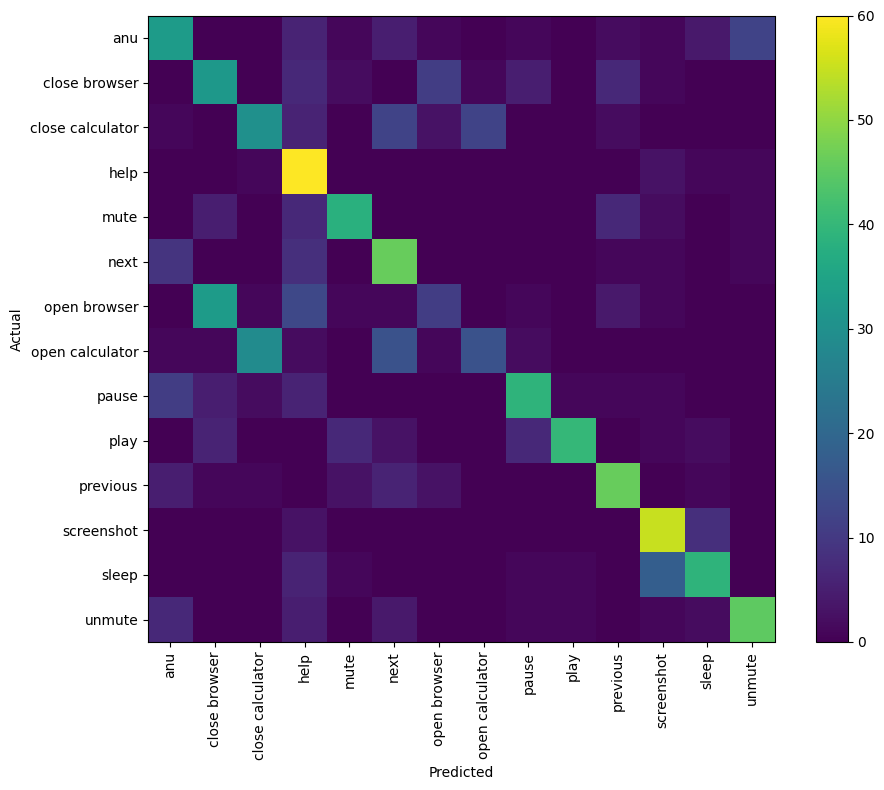

In [16]:
pred=model.predict(Xte,verbose=0).argmax(axis=1)
print("Held-out speaker accuracy:",accuracy_score(yte,pred))
print(classification_report(yte,pred,target_names=classes,zero_division=0))
cm=confusion_matrix(yte,pred)
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(cm); ax.set_xticks(range(len(classes)),classes,rotation=90)
ax.set_yticks(range(len(classes)),classes); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.colorbar(im,ax=ax); plt.tight_layout()
plt.savefig(OUT/"cnn_confusion_matrix.png",dpi=200); plt.show()
model.save(OUT/"anu_cnn_final.keras")
pd.DataFrame({"true":classes[yte],"predicted":classes[pred]}).to_csv(OUT/"cnn_test_predictions.csv",index=False)

In [17]:
model.save(OUT / "anu_cnn_batchnorm_best.keras")

In [18]:
import pandas as pd

pd.DataFrame(history.history).to_csv(
    OUT / "anu_cnn_batchnorm_history.csv",
    index=False
)